# MIS 681 - Assignment 2
## Online Purchasing Dataset Analysis

This assignment analyzes online shopping behavior using Python.
The goal is to understand how website activity relates to
customer purchases.

## 1. Analyzing On-Site Behavior Metrics and Conversion Performance

This section compares PageValues, BounceRates, and ExitRates
between customers who made purchases and those who did not.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Online_Purchasing_Dataset.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,month_number
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0,2
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0,2
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0,2
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0,2
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0,2


In [2]:
# Calculate average website behavior by revenue

metrics = ["PageValues", "BounceRates", "ExitRates"]

# Group sessions by whether a purchase was made.
# Compare average behavior metrics to understand
# how purchasing and non-purchasing visitors behave differently.

summary = df.groupby("Revenue")[metrics].mean().round(2)

print(summary)

         PageValues  BounceRates  ExitRates
Revenue                                    
0              1.98         0.03       0.05
1             27.26         0.01       0.02


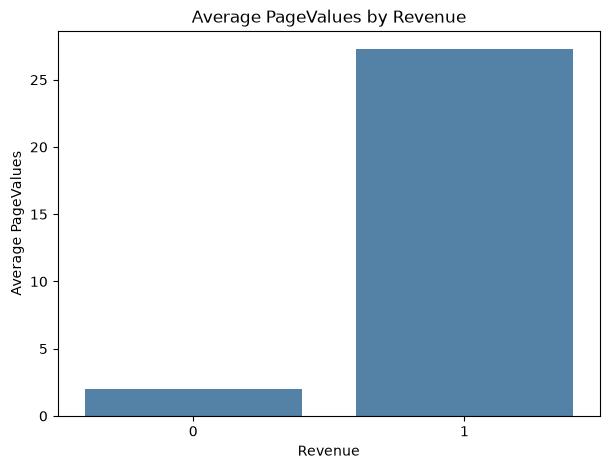

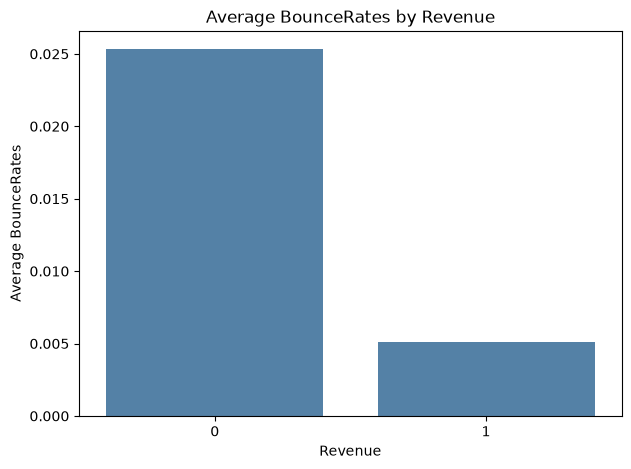

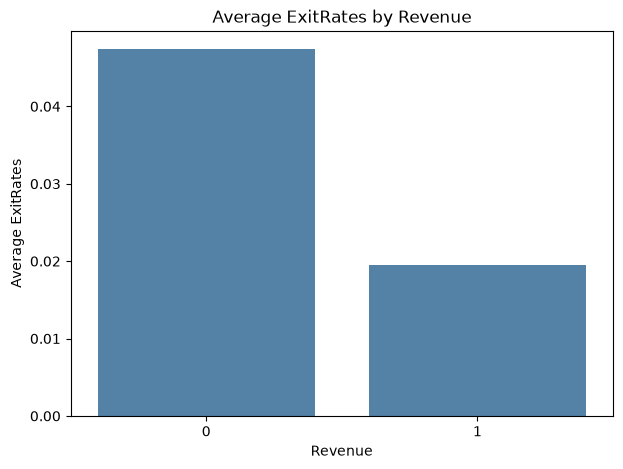

In [3]:
# Create bar charts for the three website behaviors

for metric in metrics:
    plt.figure(figsize=(7, 5))

    
    sns.barplot(data=df, x="Revenue", y=metric,
            errorbar=None, color="steelblue")


    plt.title(f"Average {metric} by Revenue")
    plt.xlabel("Revenue")
    plt.ylabel(f"Average {metric}")

    plt.show()

## 2. Weekend Impact on Conversion by Visitor Type

This section looks at whether customers are more likely to make purchases on weekends or weekdays. The results show that new visitors had higher purchase rates on weekdays, while returning visitors had higher purchase rates on weekends.

In [21]:
# Calculate average revenue by visitor type and weekend
# Compare purchase rates for each visitor type on weekdays and weekends.
# This helps show whether shopping behavior changes depending on the day.

weekend_table = pd.crosstab(
    df["VisitorType"],
    df["Weekend"],
    values=df["Revenue"],
    aggfunc="mean"
)

print(weekend_table)

Weekend               False     True 
VisitorType                          
New_Visitor        0.260905  0.219207
Other              0.192308  0.142857
Returning_Visitor  0.131840  0.164987


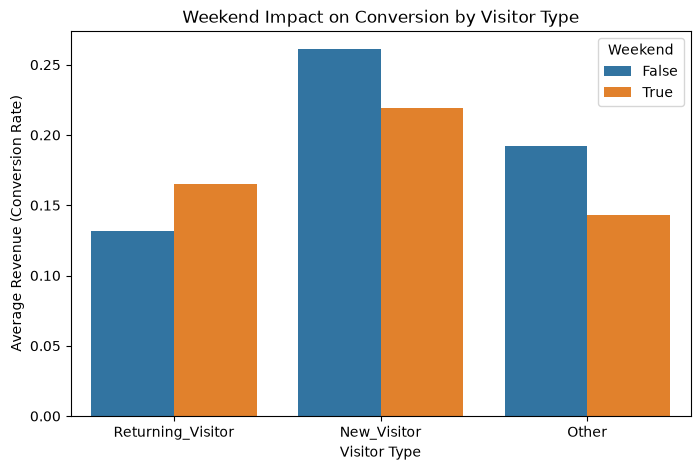

In [5]:
# Compare purchase rates by visitor type and weekend

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="VisitorType", y="Revenue",
            hue="Weekend", errorbar=None)

plt.title("Weekend Impact on Conversion by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Average Revenue (Conversion Rate)")
plt.legend(title="Weekend")

plt.show()

## 3. Seasonal Trends in Visitor Loyalty

This section compares new and returning visitors throughout the year. The results show that returning visitors made up the majority of website visits in most months.

In [22]:
# Convert month names into numbers
# This allows us to compare visitor types across different months
# and see if returning visitors are more common during certain seasons.

df["month_number"] = pd.to_datetime(
    df["Month"], format="%b", errors="coerce"
).dt.month

df.loc[df["Month"] == "June", "month_number"] = 6

# Sort the months in calendar order so the charts
# show how visitor behavior changes throughout the year.

month_order = (
    df[["Month", "month_number"]]
    .drop_duplicates()
    .sort_values("month_number")["Month"]
    .tolist()
)

print(month_order)

['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


In [7]:
# Calculate the percentage of each visitor type by month

visitor_table = pd.crosstab(
    df["Month"],
    df["VisitorType"],
    normalize="index"
) * 100

# Put months in the correct order and round to 2 decimals
visitor_table = visitor_table.reindex(month_order).round(2)

print(visitor_table)

VisitorType  New_Visitor  Other  Returning_Visitor
Month                                             
Feb                 0.54   0.00              99.46
Mar                12.17   0.00              87.83
May                 9.48   0.00              90.52
June               10.42   0.35              89.24
Jul                12.50   0.00              87.50
Aug                16.63   0.00              83.37
Sep                24.11   0.00              75.89
Oct                22.59   0.00              77.41
Nov                13.98   0.73              85.29
Dec                19.40   3.59              77.01


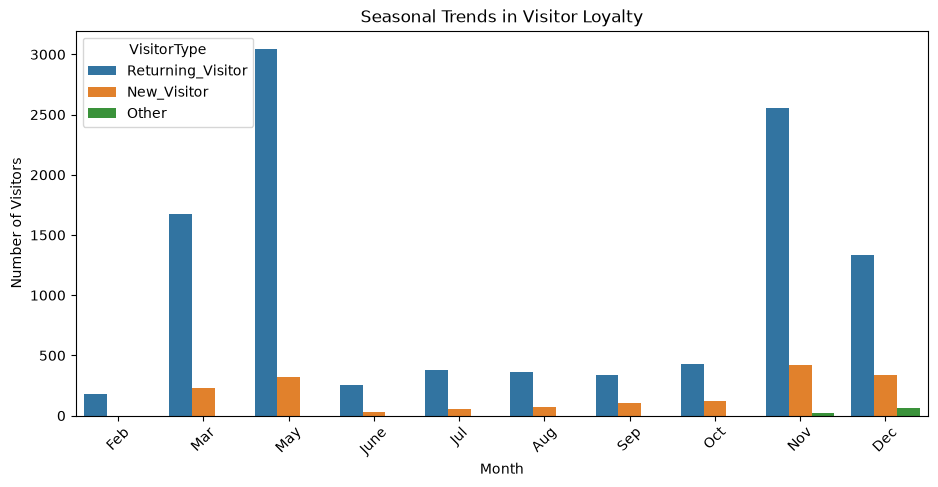

In [8]:
# Create a bar chart showing visitor types by month

plt.figure(figsize=(11, 5))

sns.countplot(data=df, x="Month", hue="VisitorType",
              order=month_order)

plt.title("Seasonal Trends in Visitor Loyalty")
plt.xlabel("Month")
plt.ylabel("Number of Visitors")
plt.xticks(rotation=45)

plt.show()

## 4. Analyzing Monthly Conversion Trends

This section looks at how purchase rates change each month. November had the highest purchase rate at 25%, while February had the lowest at 2%.


In [23]:
# Calculate the average revenue for each month
# This helps identify which months have the highest
# and lowest percentage of visitors making purchases.

monthly_conversion = (
    df.groupby(["Month", "month_number"])["Revenue"]
    .mean()
    .reset_index()
    .sort_values("month_number")
    .reset_index(drop=True)
)

print(monthly_conversion[["Month", "Revenue"]].round(2))

  Month  Revenue
0   Feb     0.02
1   Mar     0.10
2   May     0.11
3  June     0.10
4   Jul     0.15
5   Aug     0.18
6   Sep     0.19
7   Oct     0.21
8   Nov     0.25
9   Dec     0.13


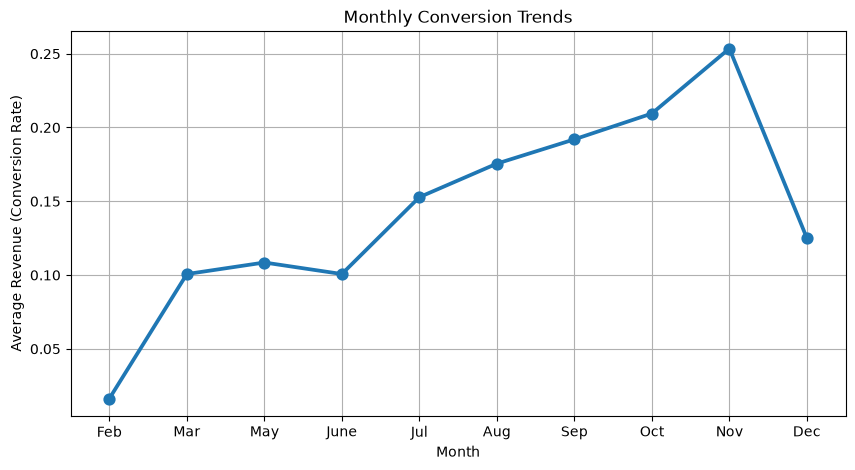

In [10]:
# Create a point plot showing monthly conversion rates

plt.figure(figsize=(10, 5))

sns.pointplot(data=df, x="Month", y="Revenue",
              order=month_order, errorbar=None)

plt.title("Monthly Conversion Trends")
plt.xlabel("Month")
plt.ylabel("Average Revenue (Conversion Rate)")
plt.grid(True)

plt.show()

## 5. Visualizing Behavioral Distributions

This section shows how much time visitors spend on different types of website pages. The graphs show that most visitors spend relatively little time on these pages, while a smaller number spend much longer.

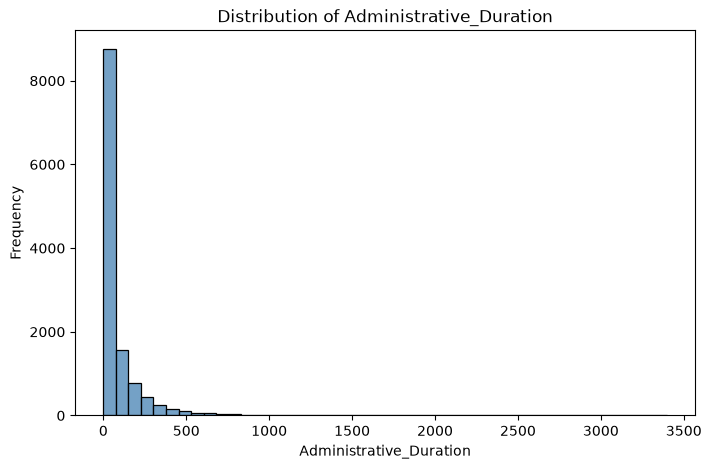

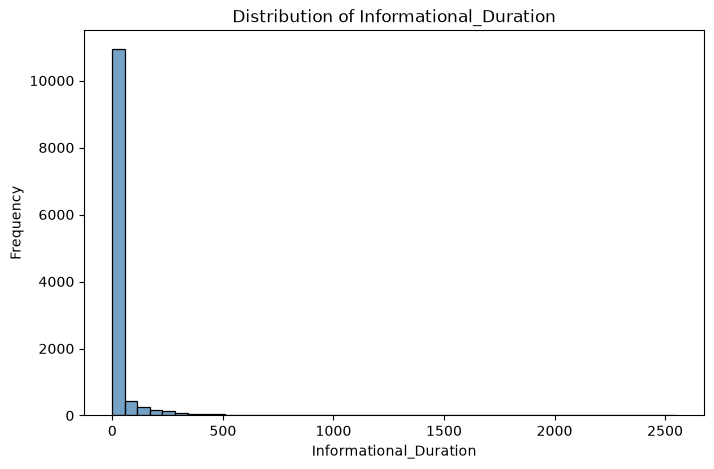

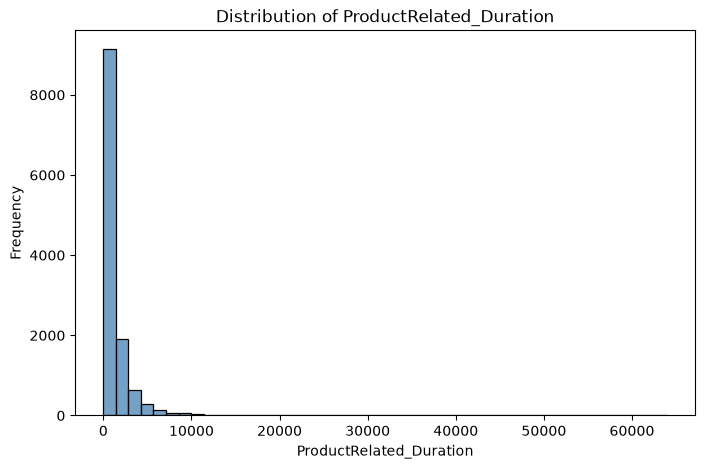

In [24]:
# Select the three website duration variables

duration_columns = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration"
]

# Create histograms to show how much time visitors spend on different pages.
# This helps us understand whether most visitors spend a short or long
# amount of time browsing the website.

for column in duration_columns:
    plt.figure(figsize=(8, 5))
    
    sns.histplot(data=df, x=column, bins=45,
             color="steelblue")


    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

## 6. Construct Session-Level Behavioral Intensity and Engagement Metrics

This section creates four new measurements to better understand how visitors use the website. These measurements help show how long customers spend on pages, how quickly they browse, and what types of pages they focus on.

In [19]:
# This function prevents division by zero when calculating
# the four new website behavior measurements.

def safe_divide(numerator, denominator):
    return numerator / denominator.replace(0, np.nan)

In [13]:
# Calculate the total time spent on pages

total_duration = (
    df["Administrative_Duration"] +
    df["Informational_Duration"] +
    df["ProductRelated_Duration"]
)

# Calculate the total number of pages visited

total_pages = (
    df["Administrative"] +
    df["Informational"] +
    df["ProductRelated"]
)

# Create the engagement score column
# Use NaN if the total number of pages is zero
# Calculate the average time spent per page during a visit.
# This helps measure how engaged visitors are with the website.

df["engagement_score"] = safe_divide(total_duration, total_pages)

# Display the results
df[[
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "engagement_score"
]]

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,engagement_score
0,0,0.0,0,0.0,1,0.000000,0.000000
1,0,0.0,0,0.0,2,64.000000,32.000000
2,0,0.0,0,0.0,1,0.000000,0.000000
3,0,0.0,0,0.0,2,2.666667,1.333333
4,0,0.0,0,0.0,10,627.500000,62.750000
...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,34.442708
12326,0,0.0,0,0.0,5,465.750000,93.150000
12327,0,0.0,0,0.0,6,184.250000,30.708333
12328,4,75.0,0,0.0,15,346.000000,22.157895


In [14]:

# Calculate visit intensity
# Use NaN when total duration is zero

df["visit_intensity"] = safe_divide(total_pages, total_duration)

# Display the results
df[[
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "visit_intensity"
]]

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,visit_intensity
0,0,0.0,0,0.0,1,0.000000,NaN
1,0,0.0,0,0.0,2,64.000000,0.031250
2,0,0.0,0,0.0,1,0.000000,NaN
3,0,0.0,0,0.0,2,2.666667,0.750000
4,0,0.0,0,0.0,10,627.500000,0.015936
...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.029034
12326,0,0.0,0,0.0,5,465.750000,0.010735
12327,0,0.0,0,0.0,6,184.250000,0.032564
12328,4,75.0,0,0.0,15,346.000000,0.045131


In [15]:

# Calculate the exit ratio
# Use NaN when BounceRates is zero

df["exit_ratio"] = safe_divide(df["ExitRates"], df["BounceRates"])

# Display the results
df[["ExitRates", "BounceRates", "exit_ratio"]]

,ExitRates,BounceRates,exit_ratio
0,0.200000,0.200000,1.000000
1,0.100000,0.000000,NaN
2,0.200000,0.200000,1.000000
3,0.140000,0.050000,2.800000
4,0.050000,0.020000,2.500000
...,...,...,...
12325,0.029031,0.007143,4.064286
12326,0.021333,0.000000,NaN
12327,0.086667,0.083333,1.040000
12328,0.021053,0.000000,NaN


In [16]:
# Calculate the information-to-product ratio
# Use NaN when ProductRelated_Duration is zero

df["info_to_prod_ratio"] = safe_divide(
    df["Informational_Duration"],
    df["ProductRelated_Duration"]
)

# Display the results
df[[
    "Informational_Duration",
    "ProductRelated_Duration",
    "info_to_prod_ratio"
]]

,Informational_Duration,ProductRelated_Duration,info_to_prod_ratio
0,0.0,0.000000,NaN
1,0.0,64.000000,0.0
2,0.0,0.000000,NaN
3,0.0,2.666667,0.0
4,0.0,627.500000,0.0
...,...,...,...
12325,0.0,1783.791667,0.0
12326,0.0,465.750000,0.0
12327,0.0,184.250000,0.0
12328,0.0,346.000000,0.0


## 7. Visualizing Session-Level Behavioral Intensity and Engagement Metrics by Conversion Outcome

This section compares the four new measurements between customers who purchased something and those who did not. The graphs help show differences in browsing behavior between the two groups.

In [17]:
# Create statistics tables for the four new measurements

new_metrics = [
    "engagement_score",
    "visit_intensity",
    "exit_ratio",
    "info_to_prod_ratio"
]

for metric in new_metrics:
    print("\nStatistics for:", metric)

    statistics = df.groupby("Revenue")[metric].describe()

    print(statistics)



Statistics for: engagement_score
           count      mean        std  min        25%        50%        75%  \
Revenue                                                                       
0        10416.0  37.03781  45.799017  0.0  17.064881  28.307348  44.267859   
1         1908.0  42.02832  26.605448  0.0  25.404241  36.259873  50.754527   

            max  
Revenue          
0        1411.0  
1         354.0  

Statistics for: visit_intensity
          count      mean       std       min       25%       50%       75%  \
Revenue                                                                       
0        9705.0  0.045689  0.073863  0.000709  0.021731  0.033317  0.052074   
1        1905.0  0.031743  0.019337  0.002825  0.019697  0.027574  0.039303   

              max  
Revenue            
0        3.333333  
1        0.277778  

Statistics for: exit_ratio
          count      mean        std       min       25%       50%       75%  \
Revenue                                

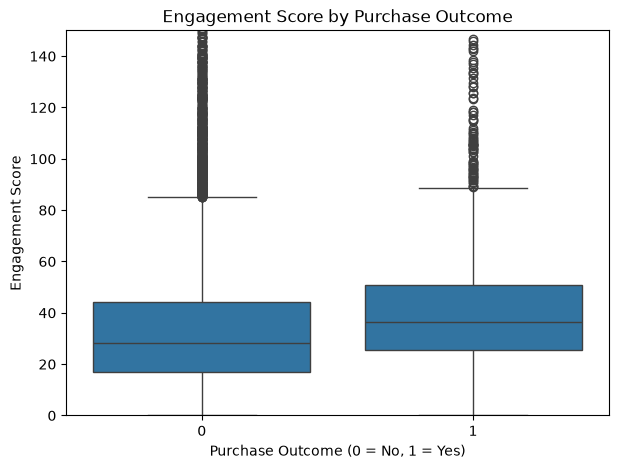

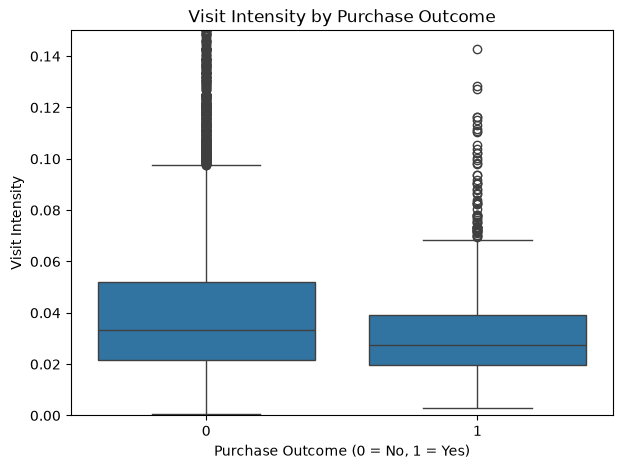

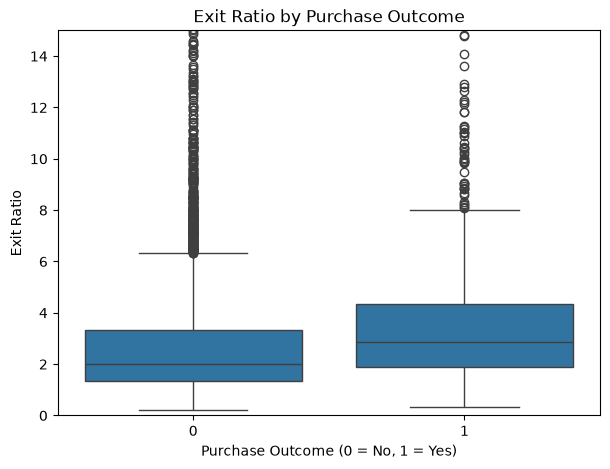

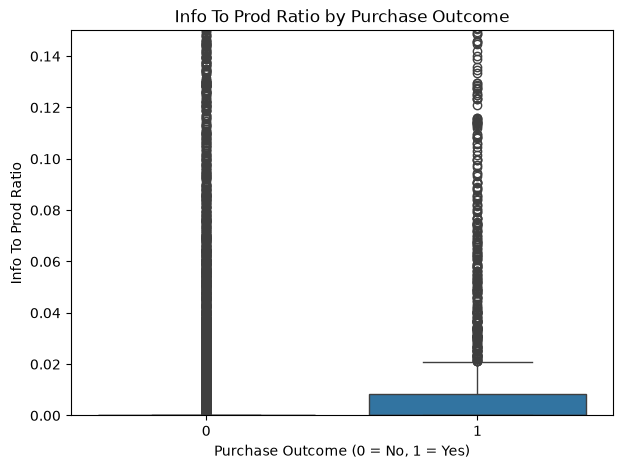

In [25]:
# Set the maximum y-axis values for each graph

y_limits = {
    "engagement_score": 150,
    "visit_intensity": 0.15,
    "exit_ratio": 15,
    "info_to_prod_ratio": 0.15
}

# Compare the four behavior measurements for visitors who made
# a purchase and those who did not.
# Boxplots help show differences in typical values and the spread of data.

for metric in new_metrics:
    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df, x="Revenue", y=metric)

    plt.title(f"{metric.replace('_', ' ').title()} by Purchase Outcome")
    plt.xlabel("Purchase Outcome (0 = No, 1 = Yes)")
    plt.ylabel(metric.replace("_", " ").title())


    plt.ylim(bottom=0, top=y_limits[metric])

    plt.show()